# Visualización y análisis de resultados.

**Descripción**.

Es posible realizar análisis y visualización de resultados previamente calculados con MODFLOW 6. En esta notebook se visualiza la solución del transporte de las especies $c_1 = Ca^{2+}$ y $c_2 =  SO_4^{2-}$ previamente calculadas y almacenadas en los subdirectorios `io_mf6/c1/gwt` y `io_mf6/c2/gwt`.

<a href="https://github.com/luiggix/RTWMA">RTWMA</a> © 2024-2026 by <a href="https://www.geofisica.unam.mx">IGF-UNAM</a> is licensed under <a href="https://creativecommons.org/licenses/by-nc/4.0/">CC BY-NC 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/nc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import flopy
import xmf6

Obtenemos los objetos de la simulación y de los modelos de transporte:

In [2]:
# Cargamos los modelos de transporte
o_sim1 = flopy.mf6.MFSimulation.load(sim_ws="io_mf6/c1/gwt", verbosity_level=0)
o_sim2 = flopy.mf6.MFSimulation.load(sim_ws="io_mf6/c2/gwt", verbosity_level=0)

# Obtenemos los objetos de los modelos
o_gwt1 = o_sim1.get_model("transport")
o_gwt2 = o_sim2.get_model("transport")

Obtenemos la información de la malla del dominio:

In [3]:
# Recuperamos las coordenadas del dominio
grid = o_gwt1.modelgrid
x = grid.xcellcenters[0] # centros de los volúmenes
nlay = grid.nlay
nrow = grid.nrow
ncol = grid.ncol

xmf6.nice_print("Discretización espacial", 
                dict(nlay = nlay, nrow = nrow, ncol = ncol, xcoord = [x]))


Discretización espacial
―――――――――――――――――――――――
  nlay = 1
  nrow = 1
  ncol = 30
xcoord = ―― INIT xcoord ――
       = [ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5 20.5 21.5 22.5 23.5 24.5 25.5 26.5 27.5
 28.5 29.5]
       = ―― END xcoord ――
―――――――――――――――――――――――


MODFLOW 6 no almacena la condición inicial por lo tanto la generamos:

In [4]:
# Arreglo para la condición inicial
c1_ini = np.full((nlay, nrow, ncol), 1.0000329) # En todo el dominio
c1_ini[0, 0, 11] = 200.0  # Pulso en x_L

# Arreglo para la condición inicial
c2_ini = np.full((nlay, nrow, ncol), 3.294e-5) # En todo el dominio
c2_ini[0, 0, 11] = 1.647e-7  # Pulso en x_L

xmf6.nice_print("Condiciones iniciales", 
                dict(c1 = c1_ini, c2 = c2_ini))


Condiciones iniciales
―――――――――――――――――――――
c1 = ―― INIT c1 ――
   = [[  1.0000329   1.0000329   1.0000329   1.0000329   1.0000329   1.0000329
    1.0000329   1.0000329   1.0000329   1.0000329   1.0000329 200.
    1.0000329   1.0000329   1.0000329   1.0000329   1.0000329   1.0000329
    1.0000329   1.0000329   1.0000329   1.0000329   1.0000329   1.0000329
    1.0000329   1.0000329   1.0000329   1.0000329   1.0000329   1.0000329]]
   = ―― END c1 ――
c2 = ―― INIT c2 ――
   = [[3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05
  3.294e-05 3.294e-05 3.294e-05 3.294e-05 1.647e-07 3.294e-05 3.294e-05
  3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05
  3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05 3.294e-05
  3.294e-05 3.294e-05]]
   = ―― END c2 ――
―――――――――――――――――――――


Construimos objetos para obtener la información de la concentración:

In [5]:
# Objetos para recuperar la concentración c1
c1_obj = o_gwt1.output.concentration()

# Objetos para recuperar la concentración c2
c2_obj = o_gwt2.output.concentration()

Revisamos cuantos pasos de tiempo tenemos en cada caso:

In [6]:
times1 = np.asarray(c1_obj.get_times())
times2 = np.asarray(c2_obj.get_times())

xmf6.nice_print("Pasos de tiempo", 
                dict(tiempos_c1 = [times1], 
                     tiempos_c2 = [times2]))


Pasos de tiempo
―――――――――――――――
tiempos_c1 = ―― INIT tiempos_c1 ――
           = [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37. 38. 39. 40.]
           = ―― END tiempos_c1 ――
tiempos_c2 = ―― INIT tiempos_c2 ――
           = [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17. 18.
 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35. 36.
 37. 38. 39. 40.]
           = ―― END tiempos_c2 ――
―――――――――――――――


Construimos dos arreglos para almacenar las concentraciones y los llenamos con la información correspondiente:

In [7]:
c1 = np.empty((len(times1)+1, len(x)), dtype=float)
c1[0] = c1_ini[0,0] # Condición inicial
c1[1:] = c1_obj.get_alldata()[:, 0, 0, :] # Resultados de 1 a 40

c2 = np.empty((len(times2)+1, len(x)), dtype=float)
c2[0] = c2_ini[0,0] # Condición inicial
c2[1:] = c2_obj.get_alldata()[:, 0, 0, :] # Resultados de 1 a 40

Finalmente hacemos la gráfica de todos los pasos de tiempo resaltando el paso $10$, la condición inicial y el paso final:

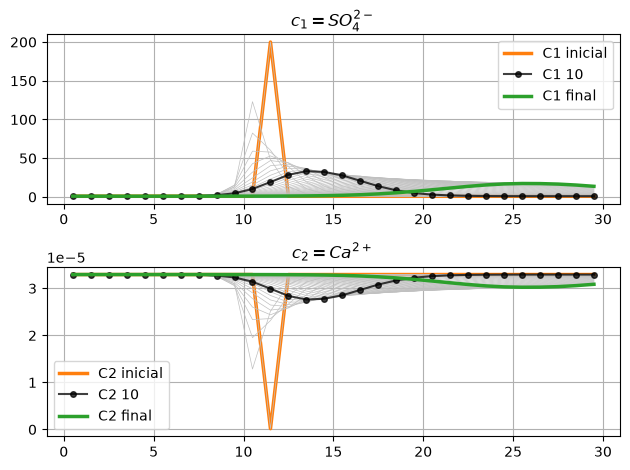

In [8]:
fig, ax = plt.subplots(2, 1)

ax[0].plot(x, c1[0], lw=2.5, ls = "-", color='C1', label = "C1 inicial")
ax[1].plot(x, c2[0], lw=2.5, ls = "-", color='C1', label = "C2 inicial")

for nt, t in enumerate(times1):
    ax[0].plot(x, c1[nt], lw=.5, color='silver')
    ax[1].plot(x, c2[nt], lw=.5, color='silver')

ax[0].plot(x, c1[10], lw=1.5, ls = "-", color='black',
          marker = "o", markersize="4", alpha = 0.75, label = "C1 10")
ax[1].plot(x, c2[10], lw=1.5, ls = "-", color='black',
          marker = "o", markersize="4", alpha = 0.75, label = "C2 10")

ax[0].plot(x, c1[-1], lw=2.5, ls = "-", color='C2',  label = "C1 final")
ax[1].plot(x, c2[-1], lw=2.5, ls = "-", color='C2',  label = "C2 final")

ax[0].set_title("$c_1 = SO_4^{2-}$")
ax[1].set_title("$c_2 = Ca^{2+}$")

ax[0].grid()
ax[1].grid()

ax[0].legend()
ax[1].legend()

plt.tight_layout()
plt.show()